In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("processed_data/initial_features.csv")

display(df.head())

print(df.shape)

,Game_ID,Player,Placement_Order,Settlement_1_Score,Settlement_2_Score,Wood_Production,Brick_Production,Sheep_Production,Wheat_Production,Ore_Production,...,Resource_Diversity,Number_Diversity,Any_Production_Probability,Initial_Wood,Initial_Brick,Initial_Sheep,Initial_Wheat,Initial_Ore,Initial_Total,Expansion_Options
0,0049a458-311f-42c8-9b38-2d675e845336,ORANGE,1,8,5,6,7,0,0,0,...,2,4,0.361111,1,1,0,0,0,2,2
1,0049a458-311f-42c8-9b38-2d675e845336,RED,2,11,4,0,0,4,7,4,...,3,3,0.305556,0,0,1,0,0,1,1
2,0049a458-311f-42c8-9b38-2d675e845336,WHITE,3,5,8,5,0,5,3,0,...,3,2,0.222222,0,0,1,1,0,2,2
3,0049a458-311f-42c8-9b38-2d675e845336,BLUE,4,8,7,1,7,4,0,3,...,4,4,0.333333,0,1,0,0,1,2,2
4,05efc4b3-9a75-47e6-ad4c-f6c3de4a8c2d,RED,1,10,9,5,2,4,5,3,...,5,5,0.472222,1,1,1,0,0,3,2


(400, 22)


In [ ]:
display(df.describe().T)

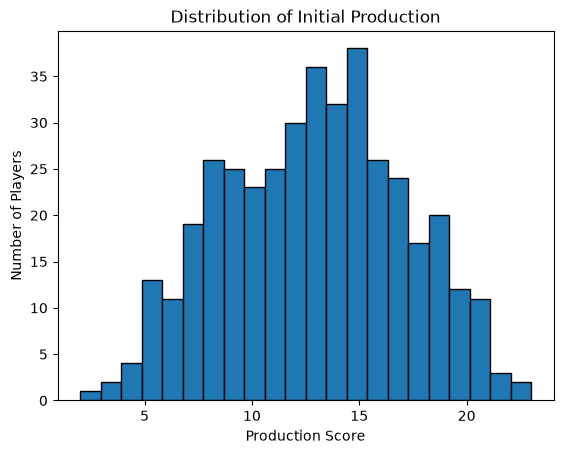

In [4]:
plt.hist(
    df["Total_Production"],
    bins=22,
    edgecolor="black"
)

plt.title("Distribution of Initial Production")
plt.xlabel("Production Score")
plt.ylabel("Number of Players")
plt.show()

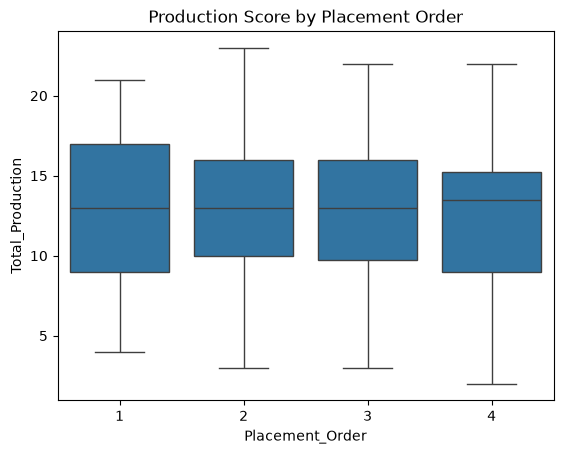

In [5]:
sns.boxplot(
    data=df,
    x="Placement_Order",
    y="Total_Production"
)

plt.title("Production Score by Placement Order")
plt.show()

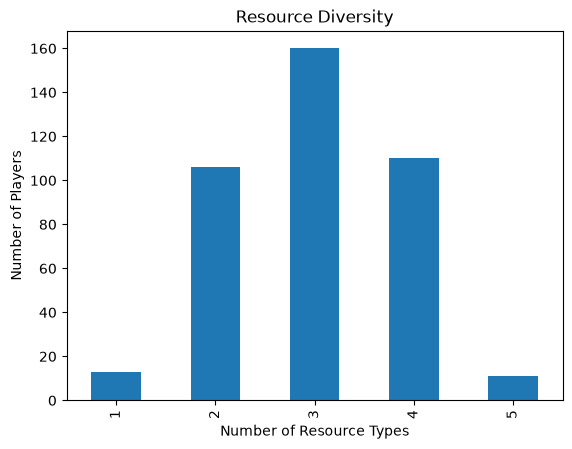

In [6]:
df["Resource_Diversity"].value_counts().sort_index().plot(
    kind="bar"
)

plt.title("Resource Diversity")
plt.xlabel("Number of Resource Types")
plt.ylabel("Number of Players")
plt.show()

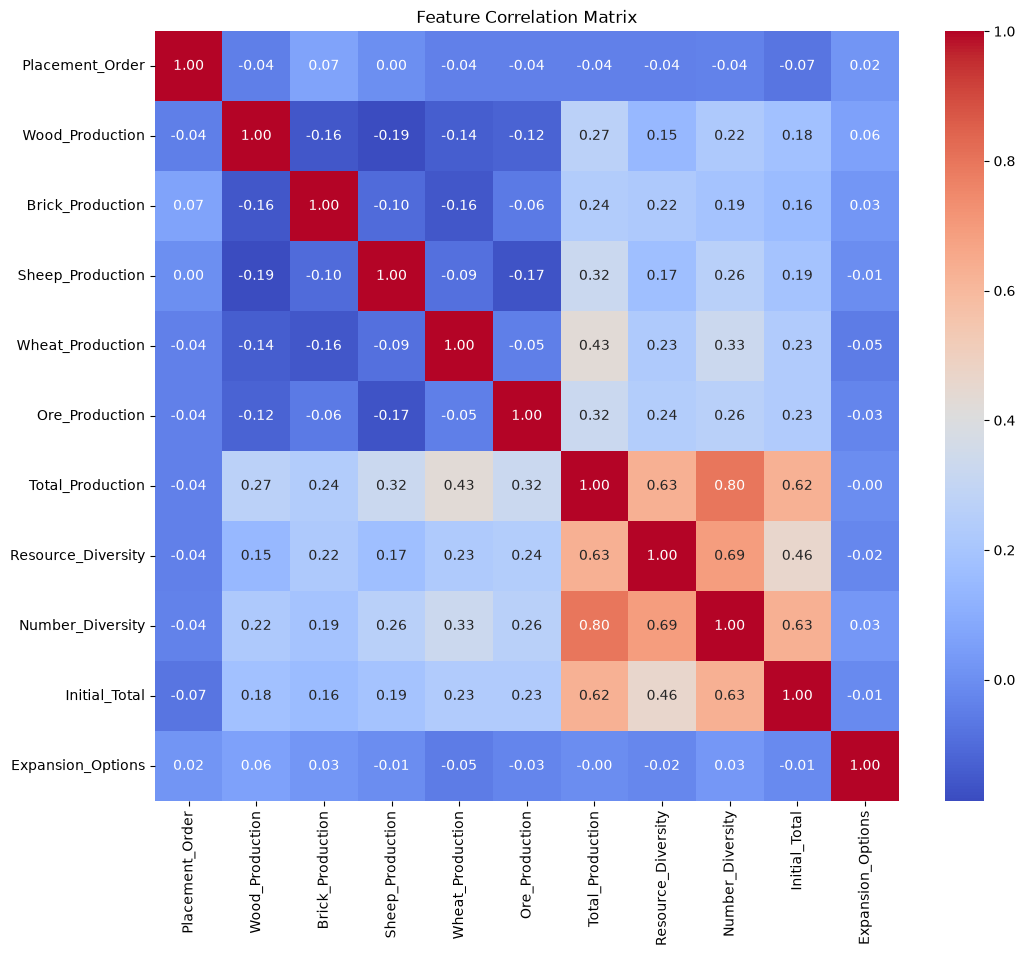

In [7]:
columns = [
    "Placement_Order",
    "Wood_Production",
    "Brick_Production",
    "Sheep_Production",
    "Wheat_Production",
    "Ore_Production",
    "Total_Production",
    "Resource_Diversity",
    "Number_Diversity",
    "Initial_Total",
    "Expansion_Options"
]

plt.figure(figsize=(12, 10))

sns.heatmap(
    df[columns].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Feature Correlation Matrix")
plt.show()

## Additional starting-position comparisons

In [ ]:
display(df.groupby("Placement_Order")[["Total_Production","Resource_Diversity","Expansion_Options","Initial_Total"]].agg(["mean","median"]))
display(df.Resource_Diversity.value_counts().sort_index())
display(df.Expansion_Options.value_counts().sort_index())
df[["Wood_Production","Brick_Production","Sheep_Production","Wheat_Production","Ore_Production"]].boxplot(rot=30)
plt.ylabel("Production pips")
plt.tight_layout()
plt.show()

In [ ]:
df.assign(Expansion_Potential=df.Expansion_Options.gt(0)).groupby("Expansion_Potential").Total_Production.describe()

These are descriptive associations under RandomPlayer placement. They are not evidence of causal advantages or winning strategies.